
# AIDev & GH Archive: Exploratory Data Analysis

## Research Overview

This notebook documents an exploratory analysis of AI coding agent contributions on GitHub using AIDev v5, GH Archive, and the GitHub REST API.

### Part 1 — Dataset Exploration
- GH Archive event collection and analysis
- AIDev dataset structure and sample inspection
- Google BigQuery validation

### Part 2 — AIDev Dataset Analysis
- Agentic PR distribution (7,685,281 PRs)
- Repository coverage and characteristics
- Full AIDev vs. AIDev-pop

### Part 3 — Cross-Dataset Integration
- Join AIDev and GH Archive using Repository ID and PR Number
- 7,394 matched PRs and 9,335 event records
- PR lifecycle analysis (Opened, Merged, Closed)

### Part 4 — Case Study and Data Validation
- Codex PR #21995: GitHub API and GH Archive validation
- Commit SHA matching
- PR merge-time analysis
- GH Archive update frequency and API comparison

## Data Sources
- [AIDev](https://huggingface.co/datasets/hao-li/AIDev)
- [GH Archive](https://www.gharchive.org/)
- [GitHub REST API](https://docs.github.com/en/rest)


In [ ]:
import gzip
import json
from pathlib import Path

file_path = Path.home() / "Desktop/AIDev & GH Archive — Exploratory Data Analysis/GHArchive_Practice/2026-03-20-12.json.gz"

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    first_event = json.loads(f.readline())

print(json.dumps(first_event, indent=2, ensure_ascii=False))

## 1. GH Archive Event Analysis


In [2]:
import gzip
import json
import pandas as pd
from collections import Counter

event_counts = Counter()
total_events = 0

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for line in f:
        event = json.loads(line)

        event_counts[event["type"]] += 1
        total_events += 1

df_counts = pd.DataFrame(
    event_counts.items(),
    columns=["Event Type", "Count"]
)

df_counts = df_counts.sort_values(
    "Count", ascending=False
).reset_index(drop=True)

print("Total events:", total_events)
display(df_counts)

Total events: 162906


,Event Type,Count
0,PushEvent,135661
1,CreateEvent,13795
2,DeleteEvent,5640
3,PullRequestEvent,2802
4,IssuesEvent,1291
5,IssueCommentEvent,1035
6,WatchEvent,818
7,PullRequestReviewCommentEvent,722
8,PullRequestReviewEvent,655
9,ReleaseEvent,213


In [3]:
import gzip
import json
import pandas as pd

pr_records = []

with gzip.open(file_path, "rt", encoding="utf-8") as f:
    for line in f:
        event = json.loads(line)

        if event["type"] == "PullRequestEvent":
            payload = event.get("payload", {})
            pr = payload.get("pull_request", {})

            pr_records.append({
                "event_id": event["id"],
                "repo": event["repo"]["name"],
                "pr_number": pr.get("number"),
                "action": payload.get("action"),
                "merged": pr.get("merged"),
                "created_at": event.get("created_at"),
                "pr_id": pr.get("id")
            })

df_pr = pd.DataFrame(pr_records)

print("Total PR events:", len(df_pr))

display(df_pr.head(10))

print("\nPR action distribution:")
display(df_pr["action"].value_counts())

Total PR events: 2802


,event_id,repo,pr_number,action,merged,created_at,pr_id
0,7594533718,dmeseguerw/spec2cloud_game,62,assigned,None,2026-03-20T12:00:26Z,3424675224
1,7594533719,dmeseguerw/spec2cloud_game,62,assigned,None,2026-03-20T12:00:26Z,3424675224
2,7594533652,liquibase/node-liquibase,133,opened,None,2026-03-20T12:00:27Z,3424675242
3,7594538023,carpentries-incubator/hpc-intro,483,opened,None,2026-03-20T12:00:37Z,3424675994
4,7594538498,SmokeBlackTime/openTrade,1,merged,None,2026-03-20T12:00:37Z,3424675275
5,7594539495,ZebraDevs/zeta-web,186,merged,None,2026-03-20T12:00:39Z,3424673667
6,7594539443,ChandanaNS/B9IS124_10539269,19,opened,None,2026-03-20T12:00:40Z,3424676191
7,7594544238,emqx/emqx-builder,155,merged,None,2026-03-20T12:00:49Z,3423707920
8,7594544214,elsadse/note-taking-app,1,opened,None,2026-03-20T12:00:51Z,3424676784
9,7594544233,tradingstrategy-ai/gmx-ccxt-middleware,1,opened,None,2026-03-20T12:00:51Z,3424676787



PR action distribution:


action
opened       1012
merged        770
labeled       759
closed         97
assigned       89
reopened       49
unlabeled      26
Name: count, dtype: int64

In [4]:
closed_pr = df_pr[df_pr["action"] == "closed"]

print("Closed PR events:", len(closed_pr))

print("Merged PR events:", (closed_pr["merged"] == True).sum())

print("Closed without merge:",
      (closed_pr["merged"] == False).sum())

Closed PR events: 97
Merged PR events: 0
Closed without merge: 0


In [5]:
# Correct PR event analysis

opened = (df_pr["action"] == "opened").sum()
merged = (df_pr["action"] == "merged").sum()
closed = (df_pr["action"] == "closed").sum()
reopened = (df_pr["action"] == "reopened").sum()

print("Opened PR events:", opened)
print("Merged PR events:", merged)
print("Closed PR events:", closed)
print("Reopened PR events:", reopened)

print("\nTotal PR events:", len(df_pr))
print("Unique PRs:", df_pr["pr_id"].nunique())

Opened PR events: 1012
Merged PR events: 770
Closed PR events: 97
Reopened PR events: 49

Total PR events: 2802
Unique PRs: 2400


In [6]:
# Inspect join keys for AIDev and GH Archive

sample = df_pr[
    ["pr_id", "repo", "pr_number", "action", "created_at"]
].head(10)

display(sample)

print("\nMissing PR IDs:")
print(df_pr["pr_id"].isna().sum())

print("\nUnique PR IDs:")
print(df_pr["pr_id"].nunique())

print("\nDuplicate PR IDs:")
print(df_pr["pr_id"].duplicated().sum())

,pr_id,repo,pr_number,action,created_at
0,3424675224,dmeseguerw/spec2cloud_game,62,assigned,2026-03-20T12:00:26Z
1,3424675224,dmeseguerw/spec2cloud_game,62,assigned,2026-03-20T12:00:26Z
2,3424675242,liquibase/node-liquibase,133,opened,2026-03-20T12:00:27Z
3,3424675994,carpentries-incubator/hpc-intro,483,opened,2026-03-20T12:00:37Z
4,3424675275,SmokeBlackTime/openTrade,1,merged,2026-03-20T12:00:37Z
5,3424673667,ZebraDevs/zeta-web,186,merged,2026-03-20T12:00:39Z
6,3424676191,ChandanaNS/B9IS124_10539269,19,opened,2026-03-20T12:00:40Z
7,3423707920,emqx/emqx-builder,155,merged,2026-03-20T12:00:49Z
8,3424676784,elsadse/note-taking-app,1,opened,2026-03-20T12:00:51Z
9,3424676787,tradingstrategy-ai/gmx-ccxt-middleware,1,opened,2026-03-20T12:00:51Z



Missing PR IDs:
0

Unique PR IDs:
2400

Duplicate PR IDs:
402


In [7]:
import requests
import pandas as pd

url = "https://datasets-server.huggingface.co/rows"

params = {
    "dataset": "hao-li/AIDev",
    "config": "all_pull_request",
    "split": "train",
    "offset": 0,
    "length": 100
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

data = response.json()

df_aidev = pd.DataFrame([
    item["row"] for item in data["rows"]
])

print("AIDev sample rows:", len(df_aidev))
print("Columns:", df_aidev.columns.tolist())

display(df_aidev.head(5))

AIDev sample rows: 100
Columns: ['id', 'number', 'title', 'user', 'user_id', 'state', 'created_at', 'closed_at', 'merged_at', 'repo_url', 'repo_id', 'html_url', 'body', 'agent']


,id,number,title,user,user_id,state,created_at,closed_at,merged_at,repo_url,repo_id,html_url,body,agent
0,3256862307,198,Show package notifications,VanDuc3724,168082585,closed,2025-07-23T15:37:57Z,2025-07-23T15:38:07Z,2025-07-23T15:38:07Z,https://api.github.com/repos/VanDuc3724/netflixx,9.994677e+08,https://github.com/VanDuc3724/netflixx/pull/198,## Summary\n- ensure success toasts display on...,OpenAI_Codex
1,3256864244,1179,Add Go solution for 670E,dvaitam,137186606,closed,2025-07-23T15:38:33Z,2025-07-23T23:36:55Z,2025-07-23T23:36:55Z,https://api.github.com/repos/dvaitam/codeforces,1.021905e+09,https://github.com/dvaitam/codeforces/pull/1179,## Summary\n- implement Go solution for contes...,OpenAI_Codex
2,3256864258,253,Switch ElectricSQL driver for web,roymichaels,187953848,closed,2025-07-23T15:38:33Z,2025-07-23T15:38:42Z,2025-07-23T15:38:42Z,https://api.github.com/repos/roymichaels/blue-...,1.012094e+09,https://github.com/roymichaels/blue-ocean/pull...,## Summary\n- use `electric-sql/browser` in th...,OpenAI_Codex
3,3256864357,763,Fix TRUTH_PATH in run_method_only,VimsRocz,96129555,closed,2025-07-23T15:38:36Z,2025-07-23T15:38:51Z,2025-07-23T15:38:51Z,https://api.github.com/repos/VimsRocz/Smart_Se...,1.001726e+09,https://github.com/VimsRocz/Smart_Sensor_Fusio...,## Summary\n- correct the `STATE_X001.txt` loc...,OpenAI_Codex
4,3256864780,94,Implement verifyJWT plugin,nemonet1337,158805284,closed,2025-07-23T15:38:41Z,2025-07-23T15:38:53Z,2025-07-23T15:38:53Z,https://api.github.com/repos/nemonet1337/VueMan,NaN,https://github.com/nemonet1337/VueMan/pull/94,## Summary\n- add a Fastify plugin `verifyJWT`...,OpenAI_Codex


In [8]:
# Ensure both join keys have the same data type
df_aidev["id"] = pd.to_numeric(df_aidev["id"], errors="coerce")
df_pr["pr_id"] = pd.to_numeric(df_pr["pr_id"], errors="coerce")

# Join AIDev with GH Archive
df_joined = df_aidev.merge(
    df_pr,
    left_on="id",
    right_on="pr_id",
    how="inner"
)

print("AIDev sample rows:", len(df_aidev))
print("GH Archive PR events:", len(df_pr))
print("Matched event rows:", len(df_joined))
print("Matched unique PRs:", df_joined["id"].nunique())

display(df_joined.head())

AIDev sample rows: 100
GH Archive PR events: 2802
Matched event rows: 0
Matched unique PRs: 0


,id,number,title,user,user_id,state,created_at_x,closed_at,merged_at,repo_url,...,html_url,body,agent,event_id,repo,pr_number,action,merged,created_at_y,pr_id


In [9]:
import requests
import pandas as pd

# 从 GH Archive 取一个真实 PR ID
target_id = int(df_pr["pr_id"].iloc[0])

url = "https://datasets-server.huggingface.co/filter"

params = {
    "dataset": "hao-li/AIDev",
    "config": "all_pull_request",
    "split": "train",
    "where": f'"id"={target_id}',
    "offset": 0,
    "length": 10
}

try:
    response = requests.get(url, params=params, timeout=30)
    response.raise_for_status()

    result = response.json()

    print("Searched PR ID:", target_id)
    print("Total matches:", result.get("num_rows_total"))
    print("Partial index:", result.get("partial"))

    matched_rows = [x["row"] for x in result.get("rows", [])]
    display(pd.DataFrame(matched_rows))

except requests.RequestException as e:
    print("API request failed:", str(e))

API request failed: 500 Server Error: Internal Server Error for url: https://datasets-server.huggingface.co/filter?dataset=hao-li%2FAIDev&config=all_pull_request&split=train&where=%22id%22%3D3424675224&offset=0&length=10


In [11]:
import gzip
import json
import pandas as pd
from pathlib import Path
from collections import Counter

data_dir = Path.home() / "Desktop/GHArchive_Practice"
files = sorted(data_dir.glob("2026-03-20-*.json.gz"))

hourly_results = []
event_counts = Counter()

for file in files:
    hour = int(file.name.split("-")[-1].split(".")[0])
    count = 0

    with gzip.open(file, "rt", encoding="utf-8") as f:
        for line in f:
            event = json.loads(line)
            event_counts[event["type"]] += 1
            count += 1

    hourly_results.append({
        "hour": hour,
        "event_count": count
    })

df_hourly = pd.DataFrame(hourly_results).sort_values("hour")

print("Files analyzed:", len(files))
print("Total events:", df_hourly["event_count"].sum())

display(df_hourly)

Files analyzed: 14
Total events: 2191536


,hour,event_count
0,10,152882
1,11,154080
2,12,162906
3,13,160930
4,14,152549
5,15,155595
6,16,164465
7,17,159226
8,18,155605
9,19,154344


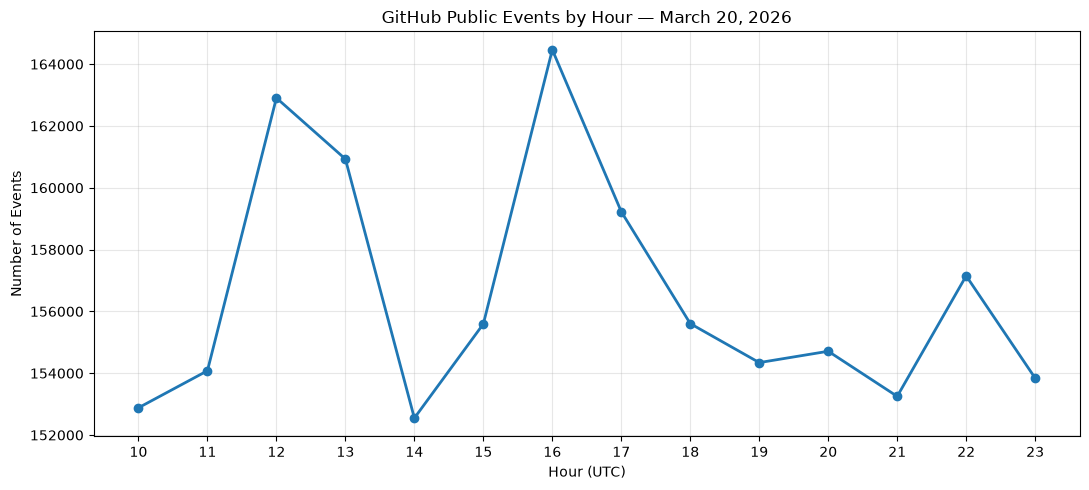

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.plot(
    df_hourly["hour"],
    df_hourly["event_count"],
    marker="o",
    linewidth=2
)

plt.title("GitHub Public Events by Hour — March 20, 2026")
plt.xlabel("Hour (UTC)")
plt.ylabel("Number of Events")

plt.xticks(df_hourly["hour"])
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("github_hourly_events.png", dpi=300)
plt.show()

In [ ]:
import requests
import pandas as pd

url = "https://datasets-server.huggingface.co/rows"

params = {
    "dataset": "hao-li/AIDev",
    "config": "all_pull_request",
    "split": "train",
    "offset": 0,
    "length": 100
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

data = response.json()

df_sample = pd.DataFrame(
    [item["row"] for item in data["rows"]]
)

print("Sample size:", len(df_sample))
print("\nAgent distribution in sample:")
print(df_sample["agent"].value_counts())

## 2. AIDev Sample Exploration


In [ ]:
import requests
import pandas as pd

offsets = [0, 100000, 500000, 1000000, 3000000, 6000000]

results = []

for offset in offsets:
    params = {
        "dataset": "hao-li/AIDev",
        "config": "all_pull_request",
        "split": "train",
        "offset": offset,
        "length": 100
    }

    try:
        response = requests.get(
            "https://datasets-server.huggingface.co/rows",
            params=params,
            timeout=30
        )
        response.raise_for_status()

        rows = response.json()["rows"]

        for item in rows:
            results.append({
                "offset": offset,
                "agent": item["row"]["agent"]
            })

        print(f"Offset {offset}: OK")

    except Exception as e:
        print(f"Offset {offset}: Failed - {e}")

df_agents = pd.DataFrame(results)

display(pd.crosstab(df_agents["offset"], df_agents["agent"]))

# Part 2: AIDev and GH Archive Data Integration

## 1. AIDev Dataset Statistics
## 2. Repository Characteristics
## 3. Cross-Dataset Matching
## 4. Pull Request Lifecycle Analysis
## 5. Commit SHA Verification
## 6. Data Source Freshness and API Comparison

In [4]:
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import huggingface_hub

print("pandas:", pd.__version__)
print("pyarrow:", pa.__version__)
print("huggingface_hub:", huggingface_hub.__version__)

pandas: 3.0.3
pyarrow: 23.0.1
huggingface_hub: 2.4.0


In [5]:
%pip install huggingface_hub

Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import pyarrow as pa
import huggingface_hub

print("pandas:", pd.__version__)
print("pyarrow:", pa.__version__)
print("huggingface_hub:", huggingface_hub.__version__)

pandas: 3.0.3
pyarrow: 23.0.1
huggingface_hub: 2.4.0


In [7]:
from huggingface_hub import HfApi

api = HfApi()

files = api.list_repo_tree(
    repo_id="hao-li/AIDev",
    repo_type="dataset",
    revision="v5",
    recursive=True
)

for file in files:
    if "all_pull_request" in file.path:
        size_gb = (file.size or 0) / (1024**3)
        print(file.path, f"{size_gb:.2f} GB")

all_pull_request.parquet 6.27 GB


In [9]:
%pip install -U fsspec aiohttp

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 548.9/548.9 kB 5.7 MB/s  0:00:00
  Attempting uninstall: yarl
    Found existing installation: yarl 1.24.2
    Uninstalling yarl-1.24.2:
      Successfully uninstalled yarl-1.24.2
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2026.4.0
    Uninstalling fsspec-2026.4.0:
      Successfully uninstalled fsspec-2026.4.0
  Attempting uninstall: aiohttp
    Found existing installation: aiohttp 3.14.1
    Uninstalling aiohttp-3.14.1:
      Successfully uninstalled aiohttp-3.14.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [aiohttp]━━━━━━━━━━ 2/3 [aiohttp]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
s3fs 2026.4.0 requires fsspec==2026.4.0, but you have fsspec 2026.9.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [10]:
import pyarrow.parquet as pq
import fsspec

url = (
    "https://huggingface.co/datasets/"
    "hao-li/AIDev/resolve/v5/all_pull_request.parquet"
)

fs = fsspec.filesystem("http")

with fs.open(url, "rb") as f:
    pf = pq.ParquetFile(f)

    print("Total rows:", pf.metadata.num_rows)
    print("Row groups:", pf.metadata.num_row_groups)
    print("Columns:", pf.schema.names)

Total rows: 7685281
Row groups: 39
Columns: ['id', 'number', 'title', 'body', 'agent', 'user_id', 'user', 'state', 'created_at', 'closed_at', 'merged_at', 'repo_id', 'repo_url', 'html_url']


## 3. AIDev Agent Distribution


In [11]:
from collections import Counter
import pyarrow.parquet as pq
import fsspec
import pandas as pd

fs = fsspec.filesystem("http")

agent_counts = Counter()

with fs.open(url, "rb") as f:
    pf = pq.ParquetFile(f)

    for i in range(pf.num_row_groups):
        table = pf.read_row_group(
            i,
            columns=["agent"]
        )

        agent_counts.update(
            table.column("agent").to_pylist()
        )

        print(f"Processed {i + 1}/{pf.num_row_groups} row groups")

df_agent_counts = pd.DataFrame(
    agent_counts.items(),
    columns=["Agent", "PR_Count"]
)

df_agent_counts["Percentage"] = (
    df_agent_counts["PR_Count"]
    / df_agent_counts["PR_Count"].sum()
    * 100
).round(2)

df_agent_counts = df_agent_counts.sort_values(
    "PR_Count", ascending=False
)

display(df_agent_counts)

print("Total PRs:", df_agent_counts["PR_Count"].sum())

Processed 1/39 row groups
Processed 2/39 row groups
Processed 3/39 row groups
Processed 4/39 row groups
Processed 5/39 row groups
Processed 6/39 row groups
Processed 7/39 row groups
Processed 8/39 row groups
Processed 9/39 row groups
Processed 10/39 row groups
Processed 11/39 row groups
Processed 12/39 row groups
Processed 13/39 row groups
Processed 14/39 row groups
Processed 15/39 row groups
Processed 16/39 row groups
Processed 17/39 row groups
Processed 18/39 row groups
Processed 19/39 row groups
Processed 20/39 row groups
Processed 21/39 row groups
Processed 22/39 row groups
Processed 23/39 row groups
Processed 24/39 row groups
Processed 25/39 row groups
Processed 26/39 row groups
Processed 27/39 row groups
Processed 28/39 row groups
Processed 29/39 row groups
Processed 30/39 row groups
Processed 31/39 row groups
Processed 32/39 row groups
Processed 33/39 row groups
Processed 34/39 row groups
Processed 35/39 row groups
Processed 36/39 row groups
Processed 37/39 row groups
Processed 

,Agent,PR_Count,Percentage
0,OpenAI_Codex,3844602,50.03
5,Copilot,1581924,20.58
3,Claude_Code,1567100,20.39
1,Cursor,317453,4.13
4,Google_Jules,296411,3.86
2,Devin,77791,1.01


Total PRs: 7685281


## 4. Repository Coverage


In [12]:
import pyarrow.parquet as pq
import fsspec
import pandas as pd

fs = fsspec.filesystem("http")

repo_sets = {}

with fs.open(url, "rb") as f:
    pf = pq.ParquetFile(f)

    for i in range(pf.num_row_groups):
        table = pf.read_row_group(
            i,
            columns=["agent", "repo_id"]
        )

        batch = table.to_pandas()

        for agent, group in batch.groupby("agent"):
            if agent not in repo_sets:
                repo_sets[agent] = set()

            repo_sets[agent].update(
                group["repo_id"].dropna().astype("int64")
            )

        print(f"Processed {i+1}/{pf.num_row_groups}")

df_repo_counts = pd.DataFrame([
    {
        "Agent": agent,
        "Unique_Repositories": len(repos)
    }
    for agent, repos in repo_sets.items()
])

df_repo_counts = df_repo_counts.merge(
    df_agent_counts[["Agent", "PR_Count"]],
    on="Agent"
)

df_repo_counts["PRs_per_Repo"] = (
    df_repo_counts["PR_Count"]
    / df_repo_counts["Unique_Repositories"]
).round(2)

display(
    df_repo_counts.sort_values(
        "Unique_Repositories", ascending=False
    )
)

Processed 1/39
Processed 2/39
Processed 3/39
Processed 4/39
Processed 5/39
Processed 6/39
Processed 7/39
Processed 8/39
Processed 9/39
Processed 10/39
Processed 11/39
Processed 12/39
Processed 13/39
Processed 14/39
Processed 15/39
Processed 16/39
Processed 17/39
Processed 18/39
Processed 19/39
Processed 20/39
Processed 21/39
Processed 22/39
Processed 23/39
Processed 24/39
Processed 25/39
Processed 26/39
Processed 27/39
Processed 28/39
Processed 29/39
Processed 30/39
Processed 31/39
Processed 32/39
Processed 33/39
Processed 34/39
Processed 35/39
Processed 36/39
Processed 37/39
Processed 38/39
Processed 39/39


,Agent,Unique_Repositories,PR_Count,PRs_per_Repo
0,OpenAI_Codex,354337,3844602,10.85
5,Copilot,346224,1581924,4.57
3,Claude_Code,173325,1567100,9.04
1,Cursor,81786,317453,3.88
4,Google_Jules,41105,296411,7.21
2,Devin,10259,77791,7.58


In [13]:
import fsspec
import pyarrow.parquet as pq

repo_url = (
    "https://huggingface.co/datasets/"
    "hao-li/AIDev/resolve/v5/all_repository.parquet"
)

fs = fsspec.filesystem("http")

with fs.open(repo_url, "rb") as f:
    pf_repo = pq.ParquetFile(f)

    print("Total repositories:", pf_repo.metadata.num_rows)
    print("Row groups:", pf_repo.num_row_groups)
    print("\nColumns:")
    for col in pf_repo.schema.names:
        print("-", col)

Total repositories: 957209
Row groups: 5

Columns:
- id
- url
- license
- full_name
- is_forked
- language
- forks
- stars


In [14]:
import pandas as pd
import pyarrow.parquet as pq
import fsspec

fs = fsspec.filesystem("http")

# 只读取研究需要的四个字段
with fs.open(repo_url, "rb") as f:
    pf_repo = pq.ParquetFile(f)

    df_repos = pf_repo.read(
        columns=["id", "language", "stars", "forks"]
    ).to_pandas()

print("Repository records:", len(df_repos))
print("Unique Repository IDs:", df_repos["id"].nunique())

# 将每个 Agent 的 Repository ID 转为对应记录
agent_repo_records = []

for agent, repo_ids in repo_sets.items():
    for repo_id in repo_ids:
        agent_repo_records.append({
            "agent": agent,
            "repo_id": repo_id
        })

df_agent_repos = pd.DataFrame(agent_repo_records)

# 关联 Repository 特征
df_merged = df_agent_repos.merge(
    df_repos,
    left_on="repo_id",
    right_on="id",
    how="left",
    validate="many_to_one"
)

print("Agent-Repository pairs:", len(df_merged))
print("Missing Repository metadata:",
      df_merged["id"].isna().sum())

display(df_merged.head(10))


Repository records: 957209
Unique Repository IDs: 957209
Agent-Repository pairs: 1007036
Missing Repository metadata: 0


,agent,repo_id,id,language,stars,forks
0,OpenAI_Codex,1150287883,1150287883,HTML,0.0,0.0
1,OpenAI_Codex,1042284558,1042284558,JavaScript,0.0,0.0
2,OpenAI_Codex,993001491,993001491,NaN,0.0,0.0
3,OpenAI_Codex,1084227606,1084227606,PHP,0.0,0.0
4,OpenAI_Codex,717226006,717226006,C#,0.0,0.0
5,OpenAI_Codex,1052770329,1052770329,TypeScript,0.0,0.0
6,OpenAI_Codex,1071644700,1071644700,HTML,0.0,0.0
7,OpenAI_Codex,976224288,976224288,TypeScript,1.0,0.0
8,OpenAI_Codex,1006632999,1006632999,PHP,0.0,0.0
9,OpenAI_Codex,488636460,488636460,C++,0.0,0.0


## 5. Repository Characteristics


In [15]:
# Step 12: Repository characteristics by AI Agent

summary = (
    df_merged.groupby("agent")
    .agg(
        Repositories=("repo_id", "nunique"),
        Median_Stars=("stars", "median"),
        Median_Forks=("forks", "median"),
        Zero_Star_Rate=("stars", lambda x: (x == 0).mean() * 100)
    )
    .reset_index()
)

# Most common language for each agent
top_languages = (
    df_merged.dropna(subset=["language"])
    .groupby("agent")["language"]
    .agg(lambda x: x.value_counts().index[0] if len(x) else None)
    .reset_index(name="Top_Language")
)

summary = summary.merge(
    top_languages,
    on="agent",
    how="left"
)

summary["Zero_Star_Rate"] = summary["Zero_Star_Rate"].round(2)

display(
    summary.sort_values("Repositories", ascending=False)
)

,agent,Repositories,Median_Stars,Median_Forks,Zero_Star_Rate,Top_Language
5,OpenAI_Codex,354337,0.0,0.0,84.22,Python
1,Copilot,346224,0.0,0.0,73.00,TypeScript
0,Claude_Code,173325,0.0,0.0,58.48,TypeScript
2,Cursor,81786,0.0,0.0,84.53,TypeScript
4,Google_Jules,41105,0.0,0.0,79.99,TypeScript
3,Devin,10259,0.0,0.0,77.34,TypeScript


In [17]:
import requests
import pandas as pd

# 获取一条真实的 AIDev PR
url = "https://datasets-server.huggingface.co/rows"

params = {
    "dataset": "hao-li/AIDev",
    "config": "all_pull_request",
    "split": "train",
    "offset": 0,
    "length": 1
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

sample_pr = response.json()["rows"][0]["row"]

print("AIDev PR ID:", sample_pr["id"])
print("Repository:", sample_pr["repo_url"])
print("PR Number:", sample_pr["number"])
print("Agent:", sample_pr["agent"])
print("PR URL:", sample_pr["html_url"])

AIDev PR ID: 3256862307
Repository: https://api.github.com/repos/VanDuc3724/netflixx
PR Number: 198
Agent: OpenAI_Codex
PR URL: https://github.com/VanDuc3724/netflixx/pull/198


In [18]:
import requests

repo = "dvaitam/codeforces"
pr_number = 1179

issue = requests.get(
    f"https://api.github.com/repos/{repo}/issues/{pr_number}",
    timeout=30
)
issue.raise_for_status()

pr = requests.get(
    f"https://api.github.com/repos/{repo}/pulls/{pr_number}",
    timeout=30
)
pr.raise_for_status()

print("Issue ID:", issue.json()["id"])
print("Pull Request ID:", pr.json()["id"])
print("PR Number:", pr.json()["number"])
print("PR State:", pr.json()["state"])
print("Merged:", pr.json()["merged"])

Issue ID: 3256864244
Pull Request ID: 2689301296
PR Number: 1179
PR State: closed
Merged: True


In [19]:
import requests

repo = "0ntu/MANA"
pr_number = 22

base = f"https://api.github.com/repos/{repo}"

issue_response = requests.get(
    f"{base}/issues/{pr_number}",
    timeout=30
)

pr_response = requests.get(
    f"{base}/pulls/{pr_number}",
    timeout=30
)

print("Issue API status:", issue_response.status_code)
print("PR API status:", pr_response.status_code)

if issue_response.ok and pr_response.ok:
    issue = issue_response.json()
    pr = pr_response.json()

    print("GitHub Issue ID:", issue["id"])
    print("GitHub PR ID:", pr["id"])
    print("GH Archive ID:", 3423101757)

    print("Matches Issue ID:", 3423101757 == issue["id"])
    print("Matches PR ID:", 3423101757 == pr["id"])

Issue API status: 200
PR API status: 200
GitHub Issue ID: 4105548116
GitHub PR ID: 3423101757
GH Archive ID: 3423101757
Matches Issue ID: False
Matches PR ID: True


In [21]:
from pathlib import Path

data_dir = Path.home() / "Desktop/GHArchive_Practice"
files = sorted(data_dir.glob("2026-03-20-*.json.gz"))

print("Folder exists:", data_dir.exists())
print("Files found:", len(files))
print("Records extracted:", len(records))
print("Current directory:", Path.cwd())

Folder exists: False
Files found: 0
Records extracted: 0
Current directory: /Users/huab


In [22]:
from pathlib import Path

data_dir = (
    Path.home()
    / "Desktop"
    / "AIDev & GH Archive — Exploratory Data Analysis"
    / "GHArchive_Practice"
)

files = sorted(data_dir.glob("2026-03-20-*.json.gz"))

print("Folder exists:", data_dir.exists())
print("Files found:", len(files))
print("First file:", files[0].name if files else "Not found")

Folder exists: True
Files found: 14
First file: 2026-03-20-10.json.gz


In [23]:
import gzip
import json
import pandas as pd

records = []

for file in files:
    with gzip.open(file, "rt", encoding="utf-8") as f:
        for line in f:
            event = json.loads(line)

            if event.get("type") == "PullRequestEvent":
                payload = event.get("payload", {})
                pr = payload.get("pull_request", {})

                records.append({
                    "repo_id": event.get("repo", {}).get("id"),
                    "repo_name": event.get("repo", {}).get("name"),
                    "pr_number": pr.get("number"),
                    "github_pr_id": pr.get("id"),
                    "action": payload.get("action"),
                    "event_time": event.get("created_at")
                })

df_gh_pr = pd.DataFrame(records)

print("Total PR events:", len(df_gh_pr))
print("Unique PRs:", df_gh_pr["github_pr_id"].nunique())
print("Missing repo IDs:", df_gh_pr["repo_id"].isna().sum())
print("Missing PR numbers:", df_gh_pr["pr_number"].isna().sum())

display(df_gh_pr.head())

Total PR events: 84717
Unique PRs: 65189
Missing repo IDs: 0
Missing PR numbers: 0


,repo_id,repo_name,pr_number,github_pr_id,action,event_time
0,646620802,gregreindel/llm-exe,312,3424230642,opened,2026-03-20T10:00:00Z
1,1186119553,rajneeshmahala/prttrigger,62,3424230653,opened,2026-03-20T10:00:00Z
2,1174303041,Felix-gg-cloud/ClaudeWorkspace,40,3424230643,opened,2026-03-20T10:00:00Z
3,876820988,italia/pa-website-validator-gui,141,3424217070,merged,2026-03-20T10:00:00Z
4,950084974,Wenzel/vmsifter,3,3424205159,merged,2026-03-20T10:00:11Z


In [25]:
import fsspec
import pyarrow.parquet as pq

# 使用独立变量名，避免被其他代码覆盖
aidev_parquet_url = (
    "https://huggingface.co/datasets/"
    "hao-li/AIDev/resolve/v5/all_pull_request.parquet"
)

fs = fsspec.filesystem("http")

with fs.open(aidev_parquet_url, "rb") as f:
    pf = pq.ParquetFile(f)

    print("Total rows:", pf.metadata.num_rows)
    print("Row groups:", pf.num_row_groups)

Total rows: 7685281
Row groups: 39


In [26]:
import fsspec
import pyarrow.parquet as pq
import pandas as pd

fs = fsspec.filesystem("http")

aidev_records = []

with fs.open(aidev_parquet_url, "rb") as f:
    pf = pq.ParquetFile(f)

    for i in range(pf.num_row_groups):
        table = pf.read_row_group(
            i,
            columns=["id", "repo_id", "number", "agent"]
        )

        aidev_records.append(table.to_pandas())

        print(f"Processed {i+1}/{pf.num_row_groups}")

df_aidev_join = pd.concat(
    aidev_records,
    ignore_index=True
)

print("AIDev records:", len(df_aidev_join))

print("Missing repo IDs:",
      df_aidev_join["repo_id"].isna().sum())

print("Missing PR numbers:",
      df_aidev_join["number"].isna().sum())

Processed 1/39
Processed 2/39
Processed 3/39
Processed 4/39
Processed 5/39
Processed 6/39
Processed 7/39
Processed 8/39
Processed 9/39
Processed 10/39
Processed 11/39
Processed 12/39
Processed 13/39
Processed 14/39
Processed 15/39
Processed 16/39
Processed 17/39
Processed 18/39
Processed 19/39
Processed 20/39
Processed 21/39
Processed 22/39
Processed 23/39
Processed 24/39
Processed 25/39
Processed 26/39
Processed 27/39
Processed 28/39
Processed 29/39
Processed 30/39
Processed 31/39
Processed 32/39
Processed 33/39
Processed 34/39
Processed 35/39
Processed 36/39
Processed 37/39
Processed 38/39
Processed 39/39
AIDev records: 7685281
Missing repo IDs: 44547
Missing PR numbers: 0


## 6. AIDev × GH Archive Data Integration


In [27]:
# 1. 清理缺失的 Repository ID
aidev_clean = df_aidev_join.dropna(
    subset=["repo_id", "number"]
).copy()

# 2. 统一关联字段的数据类型
aidev_clean["repo_id"] = aidev_clean["repo_id"].astype("int64")
aidev_clean["number"] = aidev_clean["number"].astype("int64")

df_gh_pr["repo_id"] = df_gh_pr["repo_id"].astype("int64")
df_gh_pr["pr_number"] = df_gh_pr["pr_number"].astype("int64")

# 3. 检查 AIDev 中组合键是否唯一
duplicates = aidev_clean.duplicated(
    subset=["repo_id", "number"]
).sum()

print("Duplicate AIDev join keys:", duplicates)

# 4. 正式进行 Data Join
df_matched = df_gh_pr.merge(
    aidev_clean,
    left_on=["repo_id", "pr_number"],
    right_on=["repo_id", "number"],
    how="inner",
    validate="many_to_one"
)

# 5. 输出匹配结果
print("Matched event rows:", len(df_matched))

print(
    "Matched unique PRs:",
    df_matched[["repo_id", "pr_number"]]
    .drop_duplicates()
    .shape[0]
)

print("\nMatched Agent distribution:")
print(df_matched.drop_duplicates(
    ["repo_id", "pr_number"]
)["agent"].value_counts())

display(df_matched.head(10))

Duplicate AIDev join keys: 0
Matched event rows: 9335
Matched unique PRs: 7394

Matched Agent distribution:
agent
Claude_Code     2984
OpenAI_Codex    2309
Copilot         1886
Cursor           131
Devin             54
Google_Jules      30
Name: count, dtype: int64


,repo_id,repo_name,pr_number,github_pr_id,action,event_time,id,number,agent
0,1174303041,Felix-gg-cloud/ClaudeWorkspace,40,3424230643,opened,2026-03-20T10:00:00Z,4106950773,40,Copilot
1,950084974,Wenzel/vmsifter,3,3424205159,merged,2026-03-20T10:00:11Z,4106919434,3,Claude_Code
2,1033711809,P3rlE/q3rally_tryout,1259,3424230428,merged,2026-03-20T10:00:34Z,4106950514,1259,OpenAI_Codex
3,1146968755,ToreniaFournieri/Kemo-Expedition,1301,3424232080,merged,2026-03-20T10:01:00Z,4106952555,1301,OpenAI_Codex
4,1182813783,LanceLRQ/ai-subtitle-tools,2,3424228018,merged,2026-03-20T10:01:01Z,4106947404,2,Claude_Code
5,194495547,jajir/HestiaStore,170,3424235828,assigned,2026-03-20T10:01:34Z,4106957251,170,Copilot
6,194495547,jajir/HestiaStore,170,3424235828,assigned,2026-03-20T10:01:34Z,4106957251,170,Copilot
7,1183269785,chainsahwead042/anton,10,3424235797,labeled,2026-03-20T10:01:34Z,4106957215,10,OpenAI_Codex
8,1088468132,mroohell-ux/timescape-demo,105,3424235839,labeled,2026-03-20T10:01:35Z,4106957266,105,OpenAI_Codex
9,1180561797,jianingjiang-dotcom/agent-wallet-management-site,11,3424236445,opened,2026-03-20T10:01:47Z,4106957995,11,Claude_Code


## 7. PR Lifecycle Analysis


In [28]:
# Step 15: PR actions after joining AIDev and GH Archive

# 1. Count event types
action_counts = (
    df_matched["action"]
    .value_counts()
    .rename_axis("Action")
    .reset_index(name="Event_Count")
)

print("Matched PR event distribution:")
display(action_counts)

# 2. Count unique PRs involved in each action
unique_pr_actions = (
    df_matched.groupby("action")["github_pr_id"]
    .nunique()
    .sort_values(ascending=False)
    .reset_index(name="Unique_PRs")
)

print("\nUnique PRs by action:")
display(unique_pr_actions)

# 3. Find PRs with both opened and merged events
pr_actions = (
    df_matched.groupby(["repo_id", "pr_number"])["action"]
    .agg(set)
)

opened_and_merged = pr_actions[
    pr_actions.apply(
        lambda actions: {"opened", "merged"}.issubset(actions)
    )
]

print(
    "\nPRs with both opened and merged events:",
    len(opened_and_merged)
)

Matched PR event distribution:


,Action,Event_Count
0,opened,3536
1,merged,2918
2,assigned,1561
3,labeled,1108
4,closed,133
5,unlabeled,60
6,reopened,15
7,unassigned,4



Unique PRs by action:


,action,Unique_PRs
0,opened,3536
1,merged,2918
2,labeled,987
3,assigned,901
4,closed,132
5,unlabeled,48
6,reopened,15
7,unassigned,4



PRs with both opened and merged events: 490


In [29]:
# Step 16: Find one PR with both opened and merged events

# 找到一个同时出现 opened 和 merged 的 PR
example_key = opened_and_merged.index[0]

repo_id, pr_number = example_key

example_events = df_matched[
    (df_matched["repo_id"] == repo_id) &
    (df_matched["pr_number"] == pr_number)
].sort_values("event_time")

print("Repository:", example_events["repo_name"].iloc[0])
print("PR Number:", pr_number)
print("Agent:", example_events["agent"].iloc[0])

print("\nGH Archive event history:")
display(
    example_events[
        ["repo_name", "pr_number", "agent",
         "action", "event_time", "id", "github_pr_id"]
    ]
)

Repository: netdata/netdata
PR Number: 21995
Agent: OpenAI_Codex

GH Archive event history:


,repo_name,pr_number,agent,action,event_time,id,github_pr_id
4448,netdata/netdata,21995,OpenAI_Codex,opened,2026-03-20T20:20:58Z,4109948020,3426688962
5321,netdata/netdata,21995,OpenAI_Codex,merged,2026-03-20T21:08:36Z,4109948020,3426688962


In [30]:
import requests

url = "https://api.github.com/repos/netdata/netdata/pulls/21995"

response = requests.get(url, timeout=30)
response.raise_for_status()

pr = response.json()

print("PR Number:", pr["number"])
print("PR ID:", pr["id"])
print("Title:", pr["title"])
print("State:", pr["state"])
print("Merged:", pr["merged"])
print("Created at:", pr["created_at"])
print("Merged at:", pr["merged_at"])
print("Head branch:", pr["head"]["ref"])

PR Number: 21995
PR ID: 3426688962
Title: refactor(go/cloudauth): adopt shared Azure auth schema for collectors and secretstore
State: closed
Merged: True
Created at: 2026-03-20T20:20:58Z
Merged at: 2026-03-20T21:08:36Z
Head branch: codex/cloudauth-azure-auth-shape


In [31]:
import requests
import pandas as pd

url = "https://api.github.com/repos/netdata/netdata/pulls/21995/commits"

response = requests.get(
    url,
    params={"per_page": 100},
    timeout=30
)
response.raise_for_status()

commits = response.json()

df_commits = pd.DataFrame([
    {
        "sha": c["sha"],
        "message": c["commit"]["message"].split("\n")[0],
        "author": c["commit"]["author"]["name"],
        "date": c["commit"]["author"]["date"]
    }
    for c in commits
])

print("Commits returned:", len(df_commits))
display(df_commits)

Commits returned: 8


,sha,message,author,date
0,1c4a60562fb1c6cb219280770d61afc01cf0be87,plugin: unify azure auth config shape,ilyam8,2026-03-20T19:57:32Z
1,6073b774b04681fb0a2171d8b3aadbbe7c14536b,plugin: harden azure auth config consumers,ilyam8,2026-03-20T20:12:21Z
2,3bfc53efdb3482c8147f343b57d4357fb27b22b0,plugin: clarify azure auth mode help,ilyam8,2026-03-20T20:15:51Z
3,ae7a128ea44337e91f8e09fe539a7051354071c1,plugin: harden azure auth mode handling,ilyam8,2026-03-20T20:36:17Z
4,d8b2e1be2bc8e6bfe575e715e59a0d0d5c48de56,plugin: harden azure auth validation tests,ilyam8,2026-03-20T20:41:17Z
5,b9f3745b2540a84bb2f8c793770244e52d1ec3eb,plugin: stabilize azure auth timeout test,ilyam8,2026-03-20T20:42:00Z
6,614176cce2d699d64d84676195697517a4ac0f34,plugin: clarify azure token errors,ilyam8,2026-03-20T20:43:25Z
7,5d4f14f2fc23b069f921523829b9542ac6d7fbf4,docs(cloudauth): align azure auth mode defaults,ilyam8,2026-03-20T20:59:37Z


In [32]:
import gzip
import json
import pandas as pd

target_repo = "netdata/netdata"
target_shas = set(df_commits["sha"])

matched_pushes = []

for file in files:
    with gzip.open(file, "rt", encoding="utf-8") as f:
        for line in f:
            event = json.loads(line)

            if event.get("type") != "PushEvent":
                continue

            if event.get("repo", {}).get("name") != target_repo:
                continue

            payload = event.get("payload", {})

            for commit in payload.get("commits", []):
                if commit.get("sha") in target_shas:
                    matched_pushes.append({
                        "sha": commit["sha"],
                        "event_time": event.get("created_at"),
                        "ref": payload.get("ref"),
                        "actor": event.get("actor", {}).get("login")
                    })

df_push_matches = pd.DataFrame(
    matched_pushes,
    columns=["sha", "event_time", "ref", "actor"]
)

print("PR commits:", len(target_shas))
print("Matched PushEvent records:", len(df_push_matches))
print("Unique matched SHAs:",
      df_push_matches["sha"].nunique())

display(df_push_matches)

PR commits: 8
Matched PushEvent records: 0
Unique matched SHAs: 0


,sha,event_time,ref,actor


In [33]:
import gzip
import json
from collections import Counter

target_repo = "netdata/netdata"

push_events = []
payload_fields = Counter()

for file in files:
    with gzip.open(file, "rt", encoding="utf-8") as f:
        for line in f:
            event = json.loads(line)

            if (
                event.get("type") == "PushEvent"
                and event.get("repo", {}).get("name") == target_repo
            ):
                payload = event.get("payload", {})

                payload_fields.update(payload.keys())

                push_events.append({
                    "time": event.get("created_at"),
                    "ref": payload.get("ref"),
                    "head": payload.get("head"),
                    "before": payload.get("before"),
                    "commits_present": "commits" in payload,
                    "commits_count": len(payload.get("commits") or [])
                })

print("Total PushEvents for netdata/netdata:", len(push_events))

print("\nAvailable payload fields:")
print(payload_fields)

print("\nSample PushEvents:")
display(pd.DataFrame(push_events).head(10))

Total PushEvents for netdata/netdata: 4

Available payload fields:
Counter({'repository_id': 4, 'push_id': 4, 'ref': 4, 'head': 4, 'before': 4})

Sample PushEvents:


,time,ref,head,before,commits_present,commits_count
0,2026-03-20T11:49:52Z,refs/heads/docs/add-cloud-d-contents-section,4131a421a9c0461e81d4c05cdaee3a3ea353c604,6ff037c224f4b18a388c4a5627e7b9c254bddaac,False,0
1,2026-03-20T11:50:07Z,refs/heads/docs/add-cloud-d-contents-section,910cba65b6e1bbaa6857a06b30afc8b2ecbfa1db,4131a421a9c0461e81d4c05cdaee3a3ea353c604,False,0
2,2026-03-20T21:08:37Z,refs/heads/master,0650102c70096fef699bef8131c0cb1466432833,5bea95c204461c1be59bb2a09b000c7f3f9a9c8a,False,0
3,2026-03-20T22:50:48Z,refs/heads/master,b802f5d5fdd9eaf5c9e3d93a018a04046be3f0e5,0650102c70096fef699bef8131c0cb1466432833,False,0


In [34]:
import requests
import pandas as pd

# 读取 GitHub PR 详情
url = "https://api.github.com/repos/netdata/netdata/pulls/21995"

response = requests.get(url, timeout=30)
response.raise_for_status()

pr = response.json()

merge_sha = pr["merge_commit_sha"]

print("PR Merge Commit SHA:", merge_sha)

# 查看 GH Archive 的 PushEvent
df_push = pd.DataFrame(push_events)

print("\nGH Archive PushEvent HEAD:")
display(df_push[["time", "ref", "head", "before"]])

print("\nMerge SHA matches PushEvent HEAD:",
      merge_sha in df_push["head"].values)

PR Merge Commit SHA: 0650102c70096fef699bef8131c0cb1466432833

GH Archive PushEvent HEAD:


,time,ref,head,before
0,2026-03-20T11:49:52Z,refs/heads/docs/add-cloud-d-contents-section,4131a421a9c0461e81d4c05cdaee3a3ea353c604,6ff037c224f4b18a388c4a5627e7b9c254bddaac
1,2026-03-20T11:50:07Z,refs/heads/docs/add-cloud-d-contents-section,910cba65b6e1bbaa6857a06b30afc8b2ecbfa1db,4131a421a9c0461e81d4c05cdaee3a3ea353c604
2,2026-03-20T21:08:37Z,refs/heads/master,0650102c70096fef699bef8131c0cb1466432833,5bea95c204461c1be59bb2a09b000c7f3f9a9c8a
3,2026-03-20T22:50:48Z,refs/heads/master,b802f5d5fdd9eaf5c9e3d93a018a04046be3f0e5,0650102c70096fef699bef8131c0cb1466432833



Merge SHA matches PushEvent HEAD: True


In [35]:
import pandas as pd

# 只选择 opened 和 merged 事件
df_lifecycle = df_matched[
    df_matched["action"].isin(["opened", "merged"])
].copy()

df_lifecycle["event_time"] = pd.to_datetime(
    df_lifecycle["event_time"],
    utc=True
)

# 以 PR 为单位计算事件时间
df_times = (
    df_lifecycle.pivot_table(
        index=["repo_id", "pr_number", "agent"],
        columns="action",
        values="event_time",
        aggfunc="min"
    )
    .dropna(subset=["opened", "merged"])
    .reset_index()
)

# 计算从创建到合并的小时数
df_times["merge_hours"] = (
    df_times["merged"] - df_times["opened"]
).dt.total_seconds() / 3600

# 排除时间异常的记录
df_times = df_times[df_times["merge_hours"] >= 0]

print("PRs with complete observed lifecycle:", len(df_times))

summary = (
    df_times.groupby("agent")
    .agg(
        PR_Count=("merge_hours", "count"),
        Median_Merge_Hours=("merge_hours", "median"),
        Mean_Merge_Hours=("merge_hours", "mean")
    )
    .round(2)
    .sort_values("PR_Count", ascending=False)
)

display(summary)

PRs with complete observed lifecycle: 490


,PR_Count,Median_Merge_Hours,Mean_Merge_Hours
agent,,,
Claude_Code,245,0.07,0.36
OpenAI_Codex,151,0.01,0.21
Copilot,79,0.24,0.45
Cursor,11,0.41,1.72
Devin,3,0.58,0.42
Google_Jules,1,0.13,0.13


## 8. Merge Time Distribution


In [36]:
# Step 23: Inspect merge-time distribution

print("Total PRs:", len(df_times))

print("\nMerge time summary (minutes):")
display(
    (df_times["merge_hours"] * 60).describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
    )
)

print("\nPRs merged within 1 minute:")
print((df_times["merge_hours"] * 60 < 1).sum())

print("\nPRs merged within 5 minutes:")
print((df_times["merge_hours"] * 60 < 5).sum())

print("\nDuplicate PR keys:")
print(
    df_times.duplicated(["repo_id", "pr_number"]).sum()
)

Total PRs: 490

Merge time summary (minutes):


count    490.000000
mean      21.582007
std       67.793184
min        0.016667
10%        0.165000
25%        0.516667
50%        3.125000
75%       17.745833
90%       47.908333
95%       75.649167
99%      300.935667
max      769.033333
Name: merge_hours, dtype: float64


PRs merged within 1 minute:
168

PRs merged within 5 minutes:
271

Duplicate PR keys:
0


In [38]:
# 1. 找出合并时间不足 1 分钟的 PR
quick_prs = df_times[
    df_times["merge_hours"] * 60 < 1
].copy()

quick_prs["merge_seconds"] = (
    quick_prs["merge_hours"] * 3600
).round(1)

# 2. 每个 repo_id + pr_number 只保留一条仓库名称记录
repo_names = (
    df_matched[
        ["repo_id", "pr_number", "repo_name"]
    ]
    .dropna(subset=["repo_name"])
    .drop_duplicates(subset=["repo_id", "pr_number"])
)

# 3. 关联仓库名称
quick_prs = quick_prs.merge(
    repo_names,
    on=["repo_id", "pr_number"],
    how="left",
    validate="one_to_one"
)

# 4. 生成 GitHub PR 链接
quick_prs["github_url"] = (
    "https://github.com/"
    + quick_prs["repo_name"]
    + "/pull/"
    + quick_prs["pr_number"].astype(str)
)

# 5. 输出最快合并的 10 个 PR
display(
    quick_prs[
        ["agent", "repo_name", "pr_number",
         "merge_seconds", "github_url"]
    ]
    .sort_values("merge_seconds")
    .head(10)
)

,agent,repo_name,pr_number,merge_seconds,github_url
164,Claude_Code,illmar/AI-web-project,5,1.0,https://github.com/illmar/AI-web-project/pull/5
157,Claude_Code,FengDSP/customer-service-agent,20,1.0,https://github.com/FengDSP/customer-service-ag...
97,Claude_Code,jlaszloe6/mediaserver,19,1.0,https://github.com/jlaszloe6/mediaserver/pull/19
98,Claude_Code,jlaszloe6/mediaserver,21,1.0,https://github.com/jlaszloe6/mediaserver/pull/21
102,Claude_Code,mreismendes/2026_03_predict,8,2.0,https://github.com/mreismendes/2026_03_predict...
114,Claude_Code,drn/argus,334,2.0,https://github.com/drn/argus/pull/334
113,Claude_Code,agentic-research/rosary,51,2.0,https://github.com/agentic-research/rosary/pul...
69,Claude_Code,sxsevenxperts/XPERT.IA-Software,101,2.0,https://github.com/sxsevenxperts/XPERT.IA-Soft...
37,Claude_Code,29xh24fm6r-ctrl/PulseMasterrepo,704,2.0,https://github.com/29xh24fm6r-ctrl/PulseMaster...
109,Claude_Code,lendtrain/mortgage,3,2.0,https://github.com/lendtrain/mortgage/pull/3


In [39]:
import requests
import pandas as pd

url = "https://api.github.com/repos/netdata/netdata/events"

response = requests.get(
    url,
    params={"per_page": 100},
    timeout=30
)
response.raise_for_status()

events = response.json()

latest_event = max(
    pd.to_datetime(e["created_at"], utc=True)
    for e in events
)

request_time = pd.to_datetime(
    response.headers["Date"],
    utc=True
)

delay_minutes = (
    request_time - latest_event
).total_seconds() / 60

print("API response time:", request_time)
print("Latest returned event:", latest_event)
print("Difference (minutes):", round(delay_minutes, 2))
print("Events returned:", len(events))

API response time: 2026-11-08 07:34:18+00:00
Latest returned event: 2026-11-08 06:01:26+00:00
Difference (minutes): 92.87
Events returned: 98
